# Monday, November 9th, 2026

Last week, we discussed using the mean and/or median filters to remove salt and pepper noise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

We worked with some sample images from the course webpage, and converted them to grayscale.

In [2]:
circuit = plt.imread('circuit.png')
gray_circuit = np.mean(circuit, axis=2) # Convert the RGB circuit array to 2D grayscale

We then added salt and pepper noise to these images.

In [4]:
noisy_circuit = gray_circuit.copy()   # Initialize noisy_img as a 2D grayscale array
nrows, ncols = noisy_circuit.shape

r = np.random.random((nrows, ncols))  # Array of the same shape as noisy_img full of random floats
                                      # between 0 and 1.

salt_mask =   r > .9 # Identify 10% of entries that will be hit with salt noise
pepper_mask = r < .1 # Identify 10% of entries that will be hit with pepper noise

noisy_circuit[salt_mask]   = 1 # Add salt noise
noisy_circuit[pepper_mask] = 0 # Add pepper noise

We then applied the mean/median filter using `3` by `3` grids and ignoring any edge pixels.

In [9]:
median_filtered_circuit = noisy_circuit.copy()
mean_filtered_circuit = noisy_circuit.copy()
nrows, ncols = noisy_circuit.shape

for i in range(1,nrows-1):     # For every row other than the first and last
    for j in range(1,ncols-1): # For every column other than the first and last
        grid = noisy_circuit[i-1:i+2, j-1:j+2]     # Build a 3x3 grid centered at pixel i,j
        grid_median = np.median(grid)
        grid_mean = np.mean(grid)
        mean_filtered_circuit[i,j] = grid_mean     # Set i,j-th filtered pixel to mean of the 3x3 grid
        median_filtered_circuit[i,j] = grid_median # Set i,j-th filtered pixel to median of the 3x3 grid

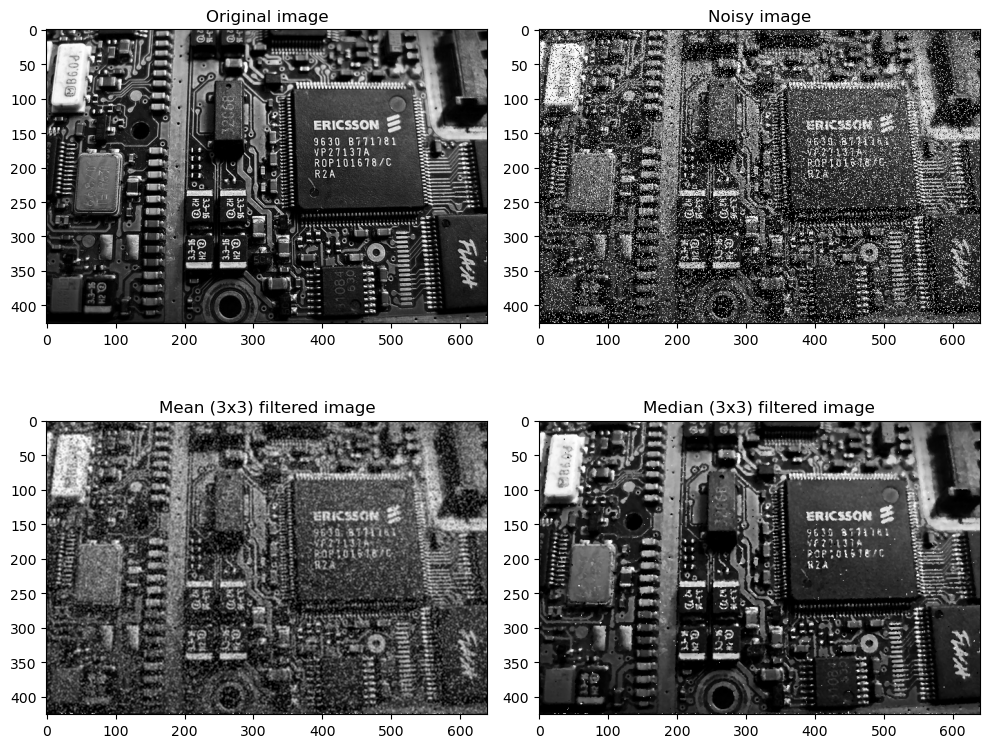

In [6]:
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.imshow(gray_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Original image')

plt.subplot(2,2,2)
plt.imshow(noisy_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Noisy image')

plt.subplot(2,2,3)
plt.imshow(mean_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Mean (3x3) filtered image')

plt.subplot(2,2,4)
plt.imshow(median_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Median (3x3) filtered image')

plt.tight_layout()

We then discussed how to modify this approach to deal with filtering pixels along the edge of the image. We accomplished this by placing the original array into a larger array (e.g. with padding).

### Handling different grid sizes

So far, we've been applying the mean/median filters using specifically a `3` by `3` grid centered on each pixel. What if we wan to use grids of different sizes, say `s=3`, `s=5`, `s=7`,...?

Let's think through how we would change our code to treat `5` by `5` grids. For now, let's again ignore the filtering of edge pixels.

In [10]:
median5_filtered_circuit = noisy_circuit.copy()
mean5_filtered_circuit = noisy_circuit.copy()
nrows, ncols = noisy_circuit.shape

for i in range(2,nrows-2):     # For every row other than the first two and last two
    for j in range(2,ncols-2): # For every column other than the first and last two
        grid = noisy_circuit[i-2:i+3, j-2:j+3]     # Build a 5x5 grid centered at pixel i,j
        grid_median = np.median(grid)
        grid_mean = np.mean(grid)
        mean5_filtered_circuit[i,j] = grid_mean     # Set i,j-th filtered pixel to mean of the 5x5 grid
        median5_filtered_circuit[i,j] = grid_median # Set i,j-th filtered pixel to median of the 5x5 grid

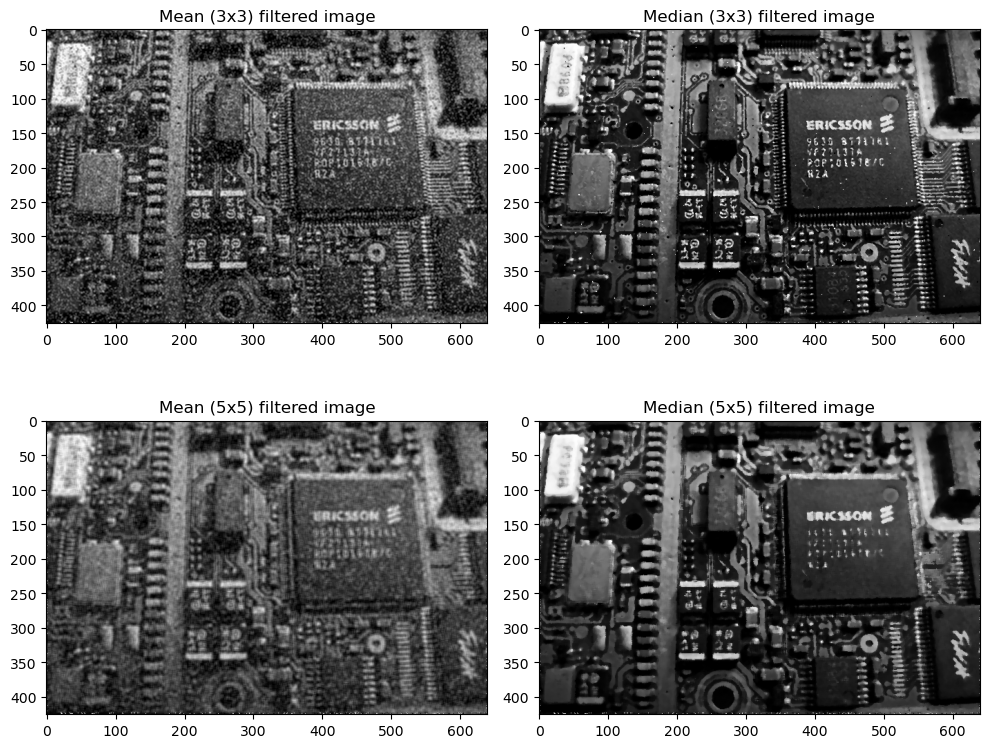

In [11]:
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.imshow(mean_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Mean (3x3) filtered image')

plt.subplot(2,2,2)
plt.imshow(median_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Median (3x3) filtered image')

plt.subplot(2,2,3)
plt.imshow(mean5_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Mean (5x5) filtered image')

plt.subplot(2,2,4)
plt.imshow(median5_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Median (5x5) filtered image')

plt.tight_layout()

What about `7` by `7` grids?

In [12]:
median7_filtered_circuit = noisy_circuit.copy()
mean7_filtered_circuit = noisy_circuit.copy()
nrows, ncols = noisy_circuit.shape

for i in range(3,nrows-3):     # For every row other than the first three and last three
    for j in range(3,ncols-3): # For every column other than the first three and last three
        grid = noisy_circuit[i-3:i+4, j-3:j+4]     # Build a 7x7 grid centered at pixel i,j
        grid_median = np.median(grid)
        grid_mean = np.mean(grid)
        mean7_filtered_circuit[i,j] = grid_mean     # Set i,j-th filtered pixel to mean of the 7x7 grid
        median7_filtered_circuit[i,j] = grid_median # Set i,j-th filtered pixel to median of the 7x7 grid

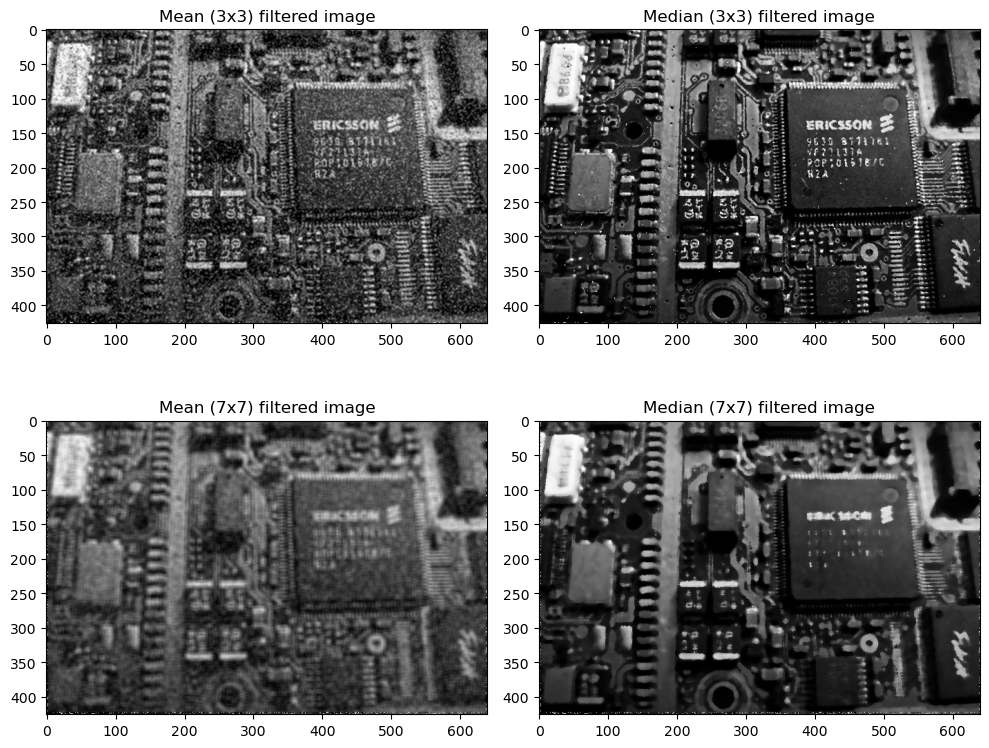

In [13]:
plt.figure(figsize=(10,8))

plt.subplot(2,2,1)
plt.imshow(mean_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Mean (3x3) filtered image')

plt.subplot(2,2,2)
plt.imshow(median_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Median (3x3) filtered image')

plt.subplot(2,2,3)
plt.imshow(mean7_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Mean (7x7) filtered image')

plt.subplot(2,2,4)
plt.imshow(median7_filtered_circuit, cmap='gray', vmin=0, vmax=1)
plt.title('Median (7x7) filtered image')

plt.tight_layout()

*Note*: The grid size `s` and the pad size `pad` are related by `pad = (s-1)//2` or `s = 2*pad + 1`.

**Exercise:** Modify the examples above to take in a parameter `s`, which is an odd integer, and apply the mean/median filter using an `s` by `s` grid. You can skip filtering any rows/columns along the edge as necessary.

### Putting things together

We've discussed how to deal with edge pixels (for the special case of `3` by `3` grids) and how to deal with varying grid sizes. We want to be able to handle both at the same time.

**Exercise:** Combine the two discussions (dealing with different grid sizes and dealing with edge pixels) to write functions `mean_filter(img, s)` and `median_filter(img,s)` that apply the mean/median filters to an input 2D array `img` using `s` by `s` grids, including all edge pixels.

## Remaining tasks to be addressed for Project 4

The exercises over the last week have asked you to create functions that accomplish the tasks that we've worked on in class. Namely, we want to have the following functions available:
 - The `sp.noise` function should take in a grayscale image array and a `noise` parameter and create a copy of the image array with salt and pepper noise added (with approximately $100\cdot$`noise`\% of the pixels being hit with salt/pepper noise).
 - The `get_padded_img` function should take in a grayscale array and a desired `pad` size  and create a padded array with `pad` additional rows at the top/bottom and `pad` additional columns at the left/right of the image array.
 - The `mean_filter` function should take in a grayscale image array and apply the mean filter, accounting for edge pixels (using the `get_padded_img` function).
 - The `median_filter` function should take in a grayscale image array and apply the median filter, accounting for edge pixels (using the `get_padded_img` function).
 - You may choose to combine the `mean_filter` and `median_filter` functions into a single function, which takes in an additional argument `filter_func` that controls the type of filter (e.g. `filter_func = np.mean` or `filter_func = np.median`).


Once you have working mean/median filters that deal with edge pixels using any odd-sized grid, you can explore how well they work on images with varying levels of noise. Does the noise level affect which filter works better? What about the grid size? Does the "best" grid size change when the amount of noise changes?

Additionally, try to think of other ways the images could be filtered. You can start from the mean/median filters and think of ways to modify or improve them, or come up with something new altogether.

## Speed - "NumPy-ifying" the process

For large images, the median filter code above is somewhat slow. It would be nice if we could use NumPy to avoid the nested `for` loop iteration through every row and column.

For reference, let's time how long it takes to apply the median filter to an image. I will use the sample code at the top of the notebook, but you should use your `median_filter` function instead.

In [14]:
import time

In [17]:
t0 = time.time()

median_filtered_circuit = noisy_circuit.copy()
nrows, ncols = noisy_circuit.shape

padded_circuit = np.zeros((nrows + 2, ncols + 2))
padded_circuit[1:-1, 1:-1] = noisy_circuit

for i in range(nrows):     # For every row other than the first and last
    for j in range(ncols): # For every column other than the first and last
        grid = padded_circuit[i:i+3, j:j+3]     # Build a 3x3 grid centered at pixel i,j
        grid_median = np.median(grid)
        median_filtered_circuit[i,j] = grid_median # Set i,j-th filtered pixel to median of the 3x3 grid

t1 = time.time()

In [18]:
print(t1 - t0)

11.41718316078186


*Idea*: Let's construct nine versions of our array. In particular, we want the following variations of the `noisy_img` array:
1. The `noisy_img` array,
2. The `noisy_img` array shifted down by one pixel,
3. The `noisy_img` array shifted up by one pixel,
4. The `noisy_img` array shifted left by one pixel,
5. The `noisy_img` array shifted right by one pixel,
6. The `noisy_img` array shifted up by one pixel and left by one pixel,
7. The `noisy_img` array shifted up by one pixel and right by one pixel,
8. The `noisy_img` array shifted down by one pixel and left by one pixel, and
9. The `noisy_img` array shifted down by one pixel and right by one pixel.

Then if we collect the `[i,j]`th entry of each of these shifted versions, we have all the values that makeup our `3` by `3` grid to compute a median.

How can we construct each of these shifted versions? We will again want to use a padded version of our array to make room for each of these shifts. We can then just take various slices of the `padded_img` array to construct these shifted versions.

In [22]:
nrows, ncols = noisy_circuit.shape
padded_circuit = np.zeros((nrows + 2, ncols + 2))
padded_circuit[1:-1, 1:-1] = noisy_circuit

shift1 = padded_circuit[2:,   1:-1]   # noisy_circuit shifted up by 1 row
shift2 = padded_circuit[1:-1, 1:-1]   # noisy_circuit unshifted
shift3 = padded_circuit[:-2,  1:-1]   # noisy_circuit shifted down by 1 row
shift4 = padded_circuit[1:-1, 0:-2]   # noisy_circuit shifted right by 1 column
shift5 = padded_circuit[1:-1, 2:]     # noisy_circuit shifted left by 1 column
shift6 = padded_circuit[2:,   0:-2]   # noisy_circuit shifted up by 1 row, right by 1 column
shift7 = padded_circuit[2:,   2:]     # noisy_circuit shifted up by 1 row, left by 1 column
shift8 = padded_circuit[:-2,  0:-2]   # noisy_circuit shifted down by 1 row, right by 1 column
shift9 = padded_circuit[:-2,  2:]     # noisy_circuit shifted down by 1 row, left by 1 column



Now that we have all of these shifted versions, we need some way to compute medians element-wise through these nine shifts. Let's create a new $4$-dimesional array, `shifts`, with the following structure:
 - Axis `0` corresponds to the pixel row in the original image.
 - Axis `1` corresponds to the pixel column in the original image.
 - Axis `2` corresponds to the row within the `3` by `3` grid of neighboring pixels in the original image.
 - Axis `3` corresponds to the column within the `3` by `3` grid of neighboring pixels in the original image.

In other words, `shifts` will have shape `(nrows, ncols, 3, 3)` and `shifts[i,j,m,n]` will store the pixel in the `[m,n]` position of `grid`, where `grid` is the `3` by `3` grid of pixels centered on pixel `[i,j]` of the original image.

In [23]:
shifts = np.zeros((nrows, ncols, 3, 3))

shifts[:, :, 0, 0] = shift8
shifts[:, :, 1, 0] = shift4
shifts[:, :, 2, 0] = shift6
shifts[:, :, 0, 1] = shift3
shifts[:, :, 1, 1] = shift2
shifts[:, :, 2, 1] = shift1
shifts[:, :, 0, 2] = shift9
shifts[:, :, 1, 2] = shift5
shifts[:, :, 2, 2] = shift7

With this new structure, we now want to compute the mean or median of each `3` by `3` grid of neighboring pixels, separately for each pixel in the original image. That is, we want to compute `np.mean(shifts[i,j])` separately for each pixel in position `[i,j]` of the original image.

Recall: The `np.mean` and `np.median` functions take in an optional argument `axis` that specify through which axes the mean/median should be computed. In our case, we want to compute the mean/median through axes `2` and `3` (i.e. the two axes that correspond to the row/column position in each `3` by `3` grid of neighboring pixels).

In [25]:
median_filtered_circuit = np.median(shifts, axis=(2,3))

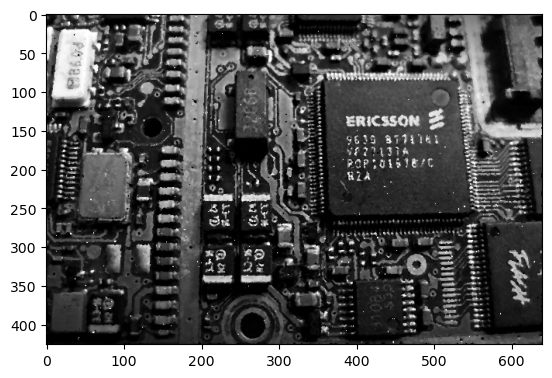

In [26]:
plt.imshow(median_filtered_circuit, cmap='gray', vmin=0, vmax=1)

Let's time it to see how this compares.

In [27]:
t0 = time.time()

nrows, ncols = noisy_circuit.shape
padded_circuit = np.zeros((nrows + 2, ncols + 2))
padded_circuit[1:-1, 1:-1] = noisy_circuit

shift1 = padded_circuit[2:,   1:-1]   # noisy_circuit shifted up by 1 row
shift2 = padded_circuit[1:-1, 1:-1]   # noisy_circuit unshifted
shift3 = padded_circuit[:-2,  1:-1]   # noisy_circuit shifted down by 1 row
shift4 = padded_circuit[1:-1, 0:-2]   # noisy_circuit shifted right by 1 column
shift5 = padded_circuit[1:-1, 2:]     # noisy_circuit shifted left by 1 column
shift6 = padded_circuit[2:,   0:-2]   # noisy_circuit shifted up by 1 row, right by 1 column
shift7 = padded_circuit[2:,   2:]     # noisy_circuit shifted up by 1 row, left by 1 column
shift8 = padded_circuit[:-2,  0:-2]   # noisy_circuit shifted down by 1 row, right by 1 column
shift9 = padded_circuit[:-2,  2:]     # noisy_circuit shifted down by 1 row, left by 1 column

shifts = np.zeros((nrows, ncols, 3, 3))
shifts[:, :, 0, 0] = shift8
shifts[:, :, 1, 0] = shift4
shifts[:, :, 2, 0] = shift6
shifts[:, :, 0, 1] = shift3
shifts[:, :, 1, 1] = shift2
shifts[:, :, 2, 1] = shift1
shifts[:, :, 0, 2] = shift9
shifts[:, :, 1, 2] = shift5
shifts[:, :, 2, 2] = shift7

median_filtered_circuit = np.median(shifts, axis=(2,3))

t1 = time.time()

In [28]:
print(t1 - t0)

0.08444833755493164


We see that this is *way* faster than our previous approach!

*Note*: In this implementation, we manually wrote out each of the nine shifted arrays that were used. Can we do this in a more algorithmic way? That is, can we have Python automatically generate these shifts? One idea is to again use a pair of nested `for` loops, but this time we iterate through lists of horizontal and vertical shifts (instead of rows and columns).

*Note*: This implementation is hard-coded to use `3` by `3` grid sizes. Can we modify it to work with any odd-sized grid?